# Data Preprocessing

Load the images, encode the labels, and split the dataset into training and validation setss

In [157]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf



from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

 Before loading images into memory, we'll create a list containing each image's location and its category, We need to connect every image to its correct category before training a classification model.

In [158]:
dataset_path = Path("../data/Waste_Dataset")

image_paths = []
labels = []

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        for image_file in folder.iterdir():
            if image_file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                image_paths.append(str(image_file))
                labels.append(folder.name)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))
print("Categories:", len(set(labels)))

Total images: 4752
Total labels: 4752
Categories: 9


This converts category names into numbers

In [159]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(labels)

print("Category mapping:")

for category, number in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{category}: {number}")

Category mapping:
1-Cardboard: 0
2-Food Organics: 1
3-Glass: 2
4-Metal: 3
5-Miscellaneous Trash: 4
6-Paper: 5
7-Plastic: 6
8-Textile Trash: 7
9-Vegetation: 8


Step 6: Split the dataset
We'll divide the 4,752 images into:
- 80% Training: Used to teach the model.
- 20% Validation: Used to evaluate the model during development.

In [160]:
X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    encoded_labels,
    test_size=0.2,
    random_state=42,
    stratify=encoded_labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

Training images: 3801
Validation images: 951


Our images are 524 × 524. We'll resize them to 224 × 224, which is a common input size for CNN and MobileNet models.


In [161]:
IMG_SIZE = 224

def load_images(paths):
    images = []

    for path in paths:
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        images.append(image)

    return np.array(images)

X_train_images = load_images(X_train)
X_val_images = load_images(X_val)

print("Training shape:", X_train_images.shape)
print("Validation shape:", X_val_images.shape)


Training shape: (3801, 224, 224, 3)
Validation shape: (951, 224, 224, 3)


We need to confirm that the images have three colour channels and that their pixel values are in the expected range.

In [162]:
print("Image shape:", X_train_images[0].shape)
print("Data type:", X_train_images.dtype)
print("Pixel range:", X_train_images.min(), "-", X_train_images.max())

Image shape: (224, 224, 3)
Data type: uint8
Pixel range: 0 - 255


Normalize the images, Smaller consistent input values generally help neural networks train more effectively.

In [163]:
X_train_normalized = X_train_images.astype("float32") / 255.0
X_val_normalized = X_val_images.astype("float32") / 255.0

print("New pixel range:", X_train_normalized.min(), "-", X_train_normalized.max())
print("Data type:", X_train_normalized.dtype)

New pixel range: 0.0 - 1.0
Data type: float32


 verify that the image still looks correct after resizing and normalization.

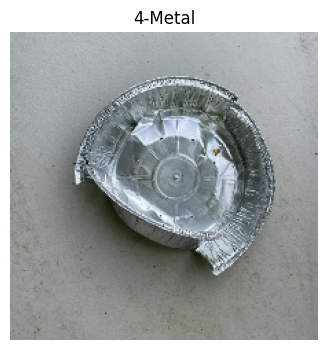

In [164]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train_normalized[0])
plt.title(label_encoder.inverse_transform([y_train[0]])[0])
plt.axis("off")
plt.show()

This function processes one image at a time when the training pipeline requests it, rather than loading the entire dataset into RAM.
Reads images from your dataset.
Converts them into RGB format.
Resizes them to 224 × 224.
Normalizes pixels to 0–1.
Prepares each image and its label for TensorFlow.

In [165]:
IMG_SIZE = 224
BATCH_SIZE = 32

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

### Create TensorFlow Datasets

Prepare training and validation data in batches of 32 images. This allows TensorFlow to load and preprocess images efficiently without loading the entire dataset into memory.

In [166]:
# Create the training dataset from image paths and labels
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

# Apply image preprocessing
train_dataset = train_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle training images to improve learning
train_dataset = train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=42
)

# Group images into batches of 32 and prepare the next batch
train_dataset = train_dataset.batch(BATCH_SIZE)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)


# Create the validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

# Apply the same preprocessing without shuffling
val_dataset = val_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group validation images into batches and prepare them efficiently
val_dataset = val_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)

Each batch should contain 32 images.,
Each image should have dimensions 224 × 224 × 3.,
Each image should have a corresponding label.,

Pixel values should be between 0 and 1.

In [167]:
# Get one batch from each dataset
train_images, train_labels = next(iter(train_dataset))
val_images, val_labels = next(iter(val_dataset))

# Check the batch shapes and pixel values
print("Training batch shape:", train_images.shape)
print("Training labels shape:", train_labels.shape)

print("Validation batch shape:", val_images.shape)
print("Validation labels shape:", val_labels.shape)

print("Pixel range:", tf.reduce_min(train_images).numpy(),
      "-", tf.reduce_max(train_images).numpy())

Training batch shape: (32, 224, 224, 3)
Training labels shape: (32,)
Validation batch shape: (32, 224, 224, 3)
Validation labels shape: (32,)
Pixel range: 0.0 - 1.0


### Custom CNN Model

Build a Convolutional Neural Network (CNN) to classify waste images into nine categories.

In [168]:
# Import the layers needed to build our CNN
from tensorflow.keras import layers, models

In [169]:
# Define the input shape for our images
input_shape = (224, 224, 3)

# Create the first convolutional layer
model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv2D(32, (3, 3), activation="relu")
])

# Reduce feature map dimensions while keeping important features using maxpooling
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

Our first convolutional layer detects basic features such as edges and simple textures.

Now we'll add another layers to learn more complex patterns

In [170]:
# Detect more complex image features,layer 2
model.add(layers.Conv2D(64, (3, 3), activation="relu"))

# Reduce the feature map size again
model.add(layers.MaxPooling2D(pool_size=(2, 2)))


# Detect more complex image features,layer 3
model.add(layers.Conv2D(128, (3, 3), activation="relu"))

# Reduce the feature map size again
model.add(layers.MaxPooling2D(pool_size=(2, 2)))


# Convert feature maps into a one-dimensional vector
#Global Average Pooling summarizes the features detected in an image into a smaller list of numbers, same as flattening,
# but it takes the average of each feature map instead of just stacking them
model.add(layers.GlobalAveragePooling2D())


# Learn how to combine the extracted features
#The Dense layer learns how to combine those features to recognize patterns associated with waste categories

model.add(layers.Dense(128, activation="relu"))




# Reduce overfitting by randomly disabling 30% of neurons during each training step.
model.add(layers.Dropout(0.3))


# Final layer that makes the actual classification.
# Classify the image into one of the nine waste categories ,because we have 9 possible outcomes, one for each waste category. 
# The softmax activation function is used to convert the output into a probability distribution over the nine classes
# sum of all probabilities of them should be equal to 1
model.add(layers.Dense(9, activation="softmax"))



# Display the CNN architecture and number of parameters
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_38 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_8      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,921 (433.29 KB)

 Trainable params: 110,921 (433.29 KB)

 Non-trainable params: 0 (0.00 B)

Compile the CNN
Configure the optimizer, loss function, and evaluation metric before training.

In [171]:
# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Training Callbacks

Prepare callbacks to monitor model performance, stop unnecessary training, and save the best model.

In [172]:
# Stop training if validation loss does not improve
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the best model during training
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="../models/custom_cnn_best.keras",
    monitor="val_loss",
    save_best_only=True
)

Train the Custom CNN
,Train the model using the training dataset and monitor its performance on the validation dataset.

In [173]:
# Train the CNN model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[early_stopping, model_checkpoint]
)

Epoch 1/20
 48/119 ━━━━━━━━━━━━━━━━━━━━ 35s 504ms/step - accuracy: 0.2032 - loss: 2.1542

KeyboardInterrupt: 

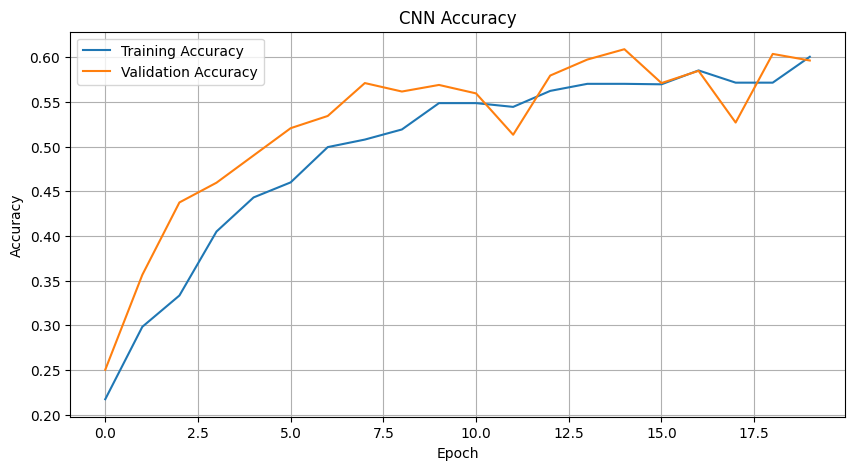

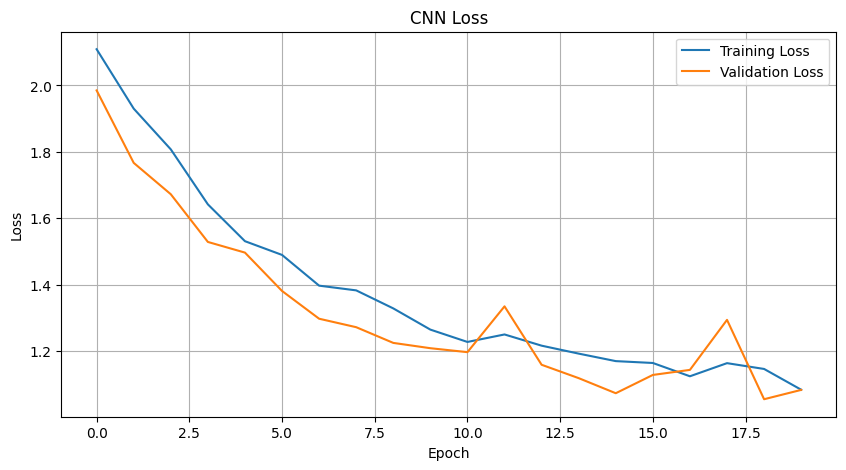

In [ ]:
# Plot training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("Epochs completed:", len(history.history["loss"]))

print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Best validation loss:", min(history.history["val_loss"]))

print("Best validation loss epoch:",
      np.argmin(history.history["val_loss"]) + 1)

print("Best validation accuracy epoch:",
      np.argmax(history.history["val_accuracy"]) + 1)

Epochs completed: 20
Final training accuracy: 0.600368320941925
Final validation accuracy: 0.5962145328521729
Final training loss: 1.0834269523620605
Final validation loss: 1.0828814506530762
Best validation accuracy: 0.608832836151123
Best validation loss: 1.0548055171966553
Best validation loss epoch: 19
Best validation accuracy epoch: 15


In [ ]:
# Load the model with the best validation loss
best_cnn_model = tf.keras.models.load_model(
    "../models/custom_cnn_best.keras"
)

# Evaluate it on the validation dataset
val_loss, val_accuracy = best_cnn_model.evaluate(val_dataset)

print("Best CNN validation loss:", val_loss)
print("Best CNN validation accuracy:", val_accuracy)

30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.6036 - loss: 1.0548
Best CNN validation loss: 1.0548055171966553
Best CNN validation accuracy: 0.6035751700401306


Classification report.It include Precision, Recall, F1-score.

In [ ]:
from sklearn.metrics import classification_report

# Get the true labels from the validation dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

# Generate model predictions
y_prob = best_cnn_model.predict(val_dataset)

# Convert probabilities into predicted class numbers
y_pred = np.argmax(y_prob, axis=1)

# Display precision, recall, and F1-score for each category
print(classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step
                       precision    recall  f1-score   support

          1-Cardboard       0.66      0.62      0.64        92
      2-Food Organics       0.70      0.70      0.70        82
              3-Glass       0.78      0.48      0.59        84
              4-Metal       0.62      0.66      0.64       158
5-Miscellaneous Trash       0.35      0.29      0.32        99
              6-Paper       0.61      0.49      0.54       100
            7-Plastic       0.60      0.77      0.67       185
      8-Textile Trash       0.31      0.25      0.28        64
         9-Vegetation       0.72      0.91      0.80        87

             accuracy                           0.60       951
            macro avg       0.60      0.57      0.58       951
         weighted avg       0.60      0.60      0.59       951



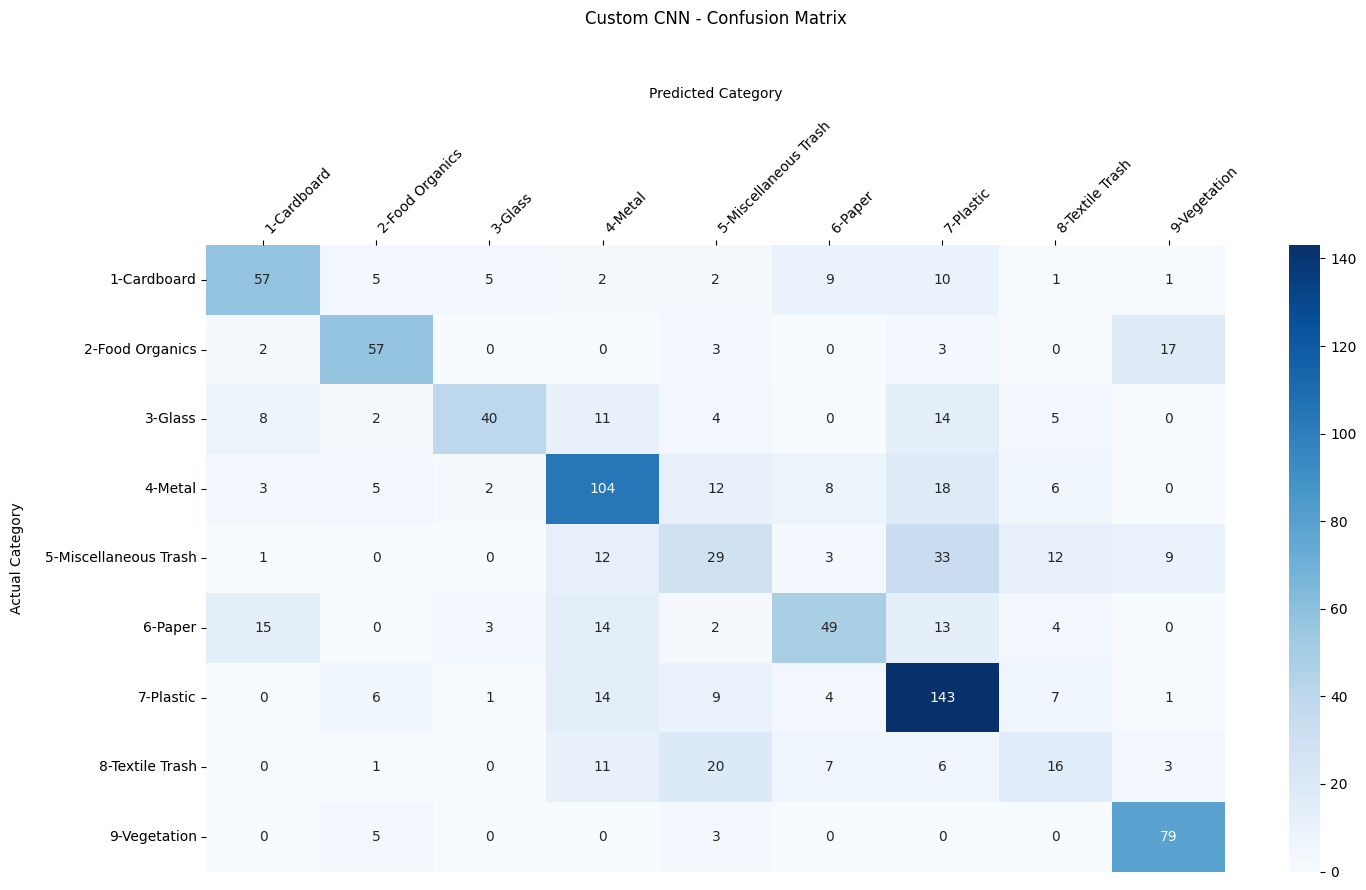

In [176]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(15, 9))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

# Move predicted category labels to the top
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Add titles and labels
plt.title("Custom CNN - Confusion Matrix", pad=45)
plt.xlabel("Predicted Category", labelpad=15)
plt.ylabel("Actual Category", labelpad=15)

# Adjust label rotation and layout
plt.xticks(rotation=45, ha="left")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "../results/figures/custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()